In [ ]:

!pip install -q medmnist


In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:

import torch
import medmnist
import matplotlib.pyplot as plt

from medmnist import ChestMNIST
from torchvision import transforms

# Check available hardware
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# Load ChestMNIST at 128x128 resolution
train_dataset = ChestMNIST(
    split="train",
    size=128,
    download=True,
    transform=transforms.ToTensor()
)

print("Training samples:", len(train_dataset))

# Inspect one sample
image, labels = train_dataset[0]

print("Image shape:", image.shape)
print("Labels shape:", labels.shape)
print("Labels:", labels)


Device: cuda
Training samples: 78468
Image shape: torch.Size([1, 128, 128])
Labels shape: (14,)
Labels: [0 0 0 0 0 0 0 0 0 0 0 0 0 0]


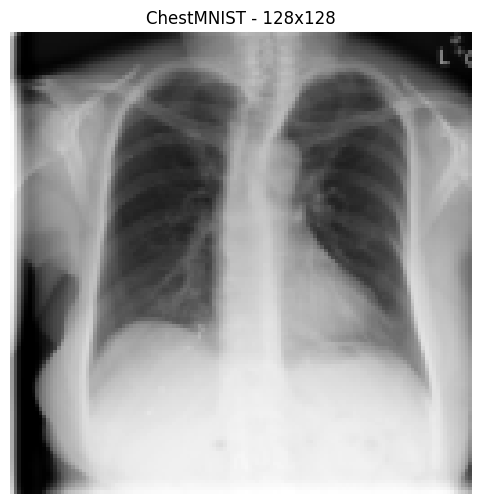

In [ ]:

plt.figure(figsize=(6, 6))

plt.imshow(
    image.squeeze(),
    cmap="gray"
)

plt.title("ChestMNIST - 128x128")
plt.axis("off")
plt.show()


      Disease  Positive Samples  Percentage
 infiltration             13914       17.73
     effusion              9261       11.80
  atelectasis              7996       10.19
       nodule              4375        5.58
         mass              3988        5.08
 pneumothorax              3705        4.72
consolidation              3263        4.16
      pleural              2279        2.90
 cardiomegaly              1950        2.49
    emphysema              1799        2.29
        edema              1690        2.15
     fibrosis              1158        1.48
    pneumonia               978        1.25
       hernia               144        0.18


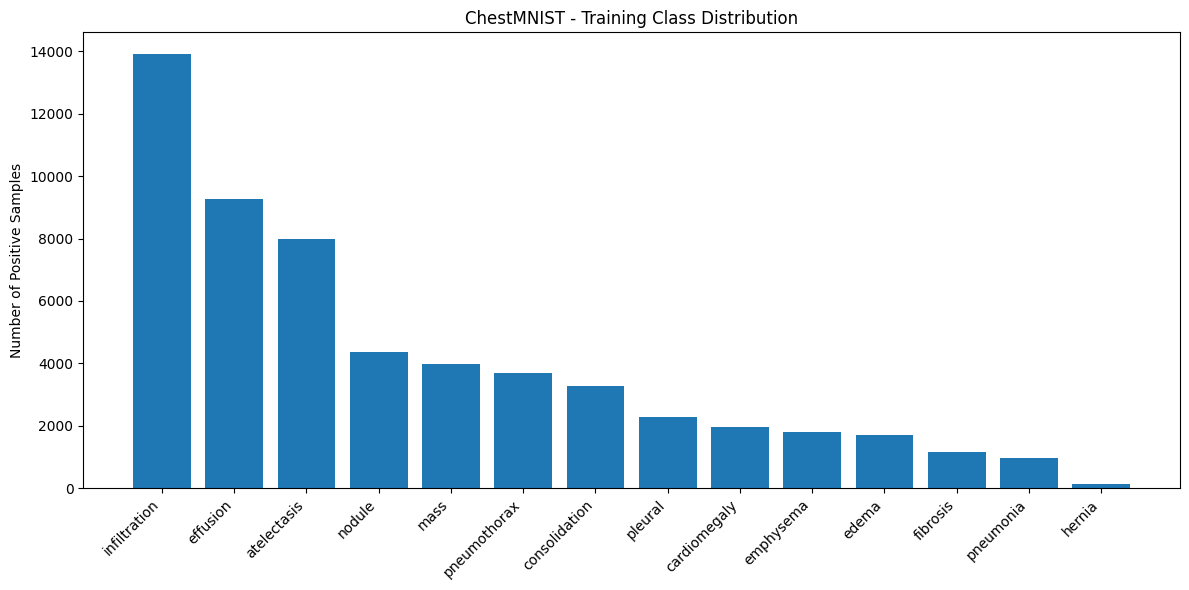

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Get all training labels
train_labels = np.array([
    train_dataset[i][1]
    for i in range(len(train_dataset))
])

# Extract class names from dataset information
class_names = list(train_dataset.info["label"].values())

# Count positive samples for each class
positive_counts = train_labels.sum(axis=0)

# Create distribution table
distribution = pd.DataFrame({
    "Disease": class_names,
    "Positive Samples": positive_counts.astype(int),
    "Percentage": (
        positive_counts / len(train_dataset) * 100
    ).round(2)
})

distribution = distribution.sort_values(
    "Positive Samples",
    ascending=False
)

print(distribution.to_string(index=False))

# Plot distribution
plt.figure(figsize=(12, 6))

plt.bar(
    distribution["Disease"],
    distribution["Positive Samples"]
)

plt.xticks(rotation=45, ha="right")
plt.ylabel("Number of Positive Samples")
plt.title("ChestMNIST - Training Class Distribution")

plt.tight_layout()
plt.show()


MULTI-LABEL DISTRIBUTION
------------------------
No positive labels: 42405
One positive label: 21602
Two positive labels: 9970
Three or more labels: 4491


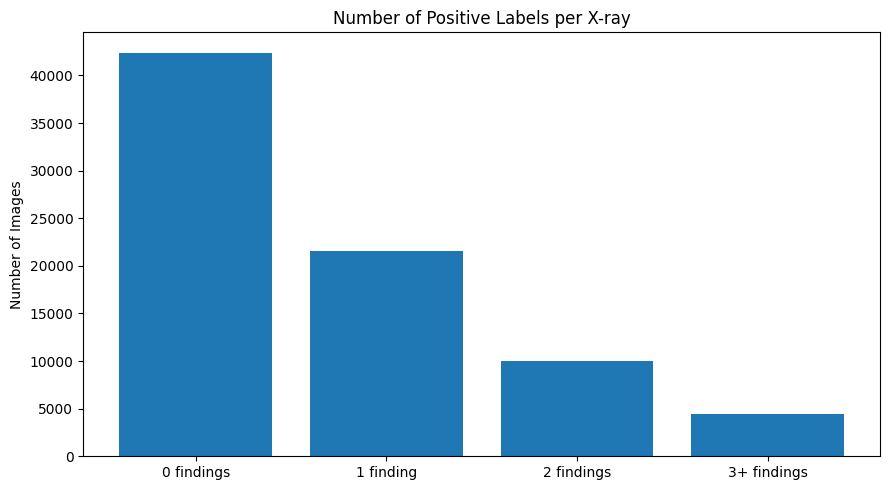

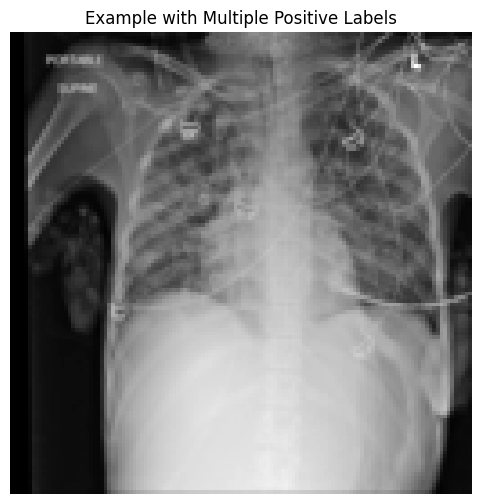

Image index: 5
Positive labels: ['infiltration', 'nodule']


In [ ]:

# Count positive labels for each image
positive_per_image = train_labels.sum(axis=1)

# Calculate image distribution
zero_labels = np.sum(positive_per_image == 0)
one_label = np.sum(positive_per_image == 1)
two_labels = np.sum(positive_per_image == 2)
three_or_more = np.sum(positive_per_image >= 3)

print("MULTI-LABEL DISTRIBUTION")
print("------------------------")
print("No positive labels:", zero_labels)
print("One positive label:", one_label)
print("Two positive labels:", two_labels)
print("Three or more labels:", three_or_more)

# Visualize distribution
categories = [
    "0 findings",
    "1 finding",
    "2 findings",
    "3+ findings"
]

counts = [
    zero_labels,
    one_label,
    two_labels,
    three_or_more
]

plt.figure(figsize=(9, 5))
plt.bar(categories, counts)

plt.ylabel("Number of Images")
plt.title("Number of Positive Labels per X-ray")

plt.tight_layout()
plt.show()


# Find an image with at least two positive labels
sample_index = np.where(positive_per_image >= 2)[0][0]

sample_image, sample_labels = train_dataset[sample_index]

detected_labels = [
    class_names[i]
    for i, value in enumerate(sample_labels)
    if value == 1
]

plt.figure(figsize=(6, 6))
plt.imshow(sample_image.squeeze(), cmap="gray")
plt.title("Example with Multiple Positive Labels")
plt.axis("off")
plt.show()

print("Image index:", sample_index)
print("Positive labels:", detected_labels)


In [ ]:

print("CLASS INDEX MAPPING")
print("-------------------")

for index, name in enumerate(class_names):
    print(f"{index}: {name}")

print("\nDataset image size:", train_dataset[0][0].size)
print("Number of classes:", len(class_names))
print("Training dataset size:", len(train_dataset))


CLASS INDEX MAPPING
-------------------
0: atelectasis
1: cardiomegaly
2: effusion
3: infiltration
4: mass
5: nodule
6: pneumonia
7: pneumothorax
8: consolidation
9: edema
10: emphysema
11: fibrosis
12: pleural
13: hernia

Dataset image size: <built-in method size of Tensor object at 0x785b3c82f9d0>
Number of classes: 14
Training dataset size: 78468


In [ ]:

import torch
import torch.nn as nn

class ChestMultiLabelCNN(nn.Module):

    def __init__(self, num_classes=14):

        super(ChestMultiLabelCNN, self).__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)

        return x


# Create model
model = ChestMultiLabelCNN().to(device)

print(model)


ChestMultiLabelCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (pool): AdaptiveAvgPool2d(output_size=(1, 1))
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=64, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=14, bias=True)
  )
)


In [ ]:

# Create a sample batch
sample_input = torch.randn(4, 1, 128, 128).to(device)

# Forward pass
with torch.no_grad():
    output = model(sample_input)

print("Input shape:", sample_input.shape)
print("Output shape:", output.shape)

print("Number of model parameters:",
      sum(p.numel() for p in model.parameters()))


Input shape: torch.Size([4, 1, 128, 128])
Output shape: torch.Size([4, 14])
Number of model parameters: 28366


In [ ]:

# Load validation dataset
val_dataset = ChestMNIST(
    split="val",
    size=128,
    download=True,
    transform=transforms.ToTensor()
)

# Load test dataset
test_dataset = ChestMNIST(
    split="test",
    size=128,
    download=True,
    transform=transforms.ToTensor()
)

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))


 85%|████████▍ | 1.21G/1.43G [09:14<01:18, 2.73MB/s]

In [ ]:

from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Train batches: 2453
Validation batches: 351
Test batches: 702


In [ ]:

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)


Image batch shape: torch.Size([32, 1, 128, 128])
Label batch shape: torch.Size([32, 14])
Image dtype: torch.float32
Label dtype: torch.int64


In [ ]:

# Define loss function
criterion = nn.BCEWithLogitsLoss()

# Define optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)


Loss function: BCEWithLogitsLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [ ]:

# Get one batch
images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.float().to(device)

# Forward pass
outputs = model(images)

# Calculate loss
loss = criterion(outputs, labels)

print("Output shape:", outputs.shape)
print("Label shape:", labels.shape)
print("Loss:", loss.item())


Output shape: torch.Size([32, 14])
Label shape: torch.Size([32, 14])
Loss: 0.6886409521102905


In [ ]:
import time

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.float().to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)


start_time = time.time()

train_loss = train_one_epoch(
    model,
    train_loader,
    criterion,
    optimizer,
    device
)

elapsed_time = time.time() - start_time

print(f"Training Loss: {train_loss:.4f}")
print(f"Training Time: {elapsed_time / 60:.2f} minutes")

Training Loss: 0.1905
Training Time: 0.50 minutes


In [ ]:
def validate_one_epoch(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.float().to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item()

    return total_loss / len(loader)


val_loss = validate_one_epoch(
    model,
    val_loader,
    criterion,
    device
)

print(f"Validation Loss: {val_loss:.4f}")

Validation Loss: 0.1800


In [ ]:
EPOCHS = 5

train_losses = []
val_losses = []

for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Validation Loss: {val_loss:.4f}"
    )

Epoch [1/5] Train Loss: 0.1833 Validation Loss: 0.1806
Epoch [2/5] Train Loss: 0.1811 Validation Loss: 0.1767
Epoch [3/5] Train Loss: 0.1792 Validation Loss: 0.1738
Epoch [4/5] Train Loss: 0.1781 Validation Loss: 0.1745
Epoch [5/5] Train Loss: 0.1773 Validation Loss: 0.1731


In [ ]:
!pip install -q scikit-learn

In [ ]:
from sklearn.metrics import classification_report, roc_auc_score
import numpy as np

In [ ]:
model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        # Logits -> probabilities
        probabilities = torch.sigmoid(outputs)

        all_predictions.append(probabilities.cpu().numpy())
        all_labels.append(labels.numpy())

all_labels = np.concatenate(all_labels)
all_predictions = np.concatenate(all_predictions)

print("True labels shape:", all_labels.shape)
print("Predictions shape:", all_predictions.shape)

True labels shape: (22433, 14)
Predictions shape: (22433, 14)


In [ ]:
from sklearn.metrics import classification_report

# 0.5 threshold ile tahminleri binary hale getiriyoruz
binary_predictions = (all_predictions >= 0.5).astype(int)

report = classification_report(
    all_labels,
    binary_predictions,
    target_names=class_names,
    zero_division=0
)

print(report)

               precision    recall  f1-score   support

  atelectasis       0.00      0.00      0.00      2420
 cardiomegaly       0.00      0.00      0.00       582
     effusion       0.00      0.00      0.00      2754
 infiltration       0.00      0.00      0.00      3938
         mass       0.00      0.00      0.00      1133
       nodule       0.00      0.00      0.00      1335
    pneumonia       0.00      0.00      0.00       242
 pneumothorax       0.00      0.00      0.00      1089
consolidation       0.00      0.00      0.00       957
        edema       0.00      0.00      0.00       413
    emphysema       0.00      0.00      0.00       509
     fibrosis       0.00      0.00      0.00       362
      pleural       0.00      0.00      0.00       734
       hernia       0.00      0.00      0.00        42

    micro avg       0.00      0.00      0.00     16510
    macro avg       0.00      0.00      0.00     16510
 weighted avg       0.00      0.00      0.00     16510
  sample

In [ ]:
print("Prediction statistics:")
print("Minimum probability:", all_predictions.min())
print("Maximum probability:", all_predictions.max())
print("Mean probability:", all_predictions.mean())

print("\nPredicted positive samples per class:")

for i, name in enumerate(class_names):
    positive_count = np.sum(all_predictions[:, i] >= 0.5)

    print(f"{name}: {positive_count}")

Prediction statistics:
Minimum probability: 1.9347067e-06
Maximum probability: 0.342974
Mean probability: 0.054096356

Predicted positive samples per class:
atelectasis: 0
cardiomegaly: 0
effusion: 0
infiltration: 0
mass: 0
nodule: 0
pneumonia: 0
pneumothorax: 0
consolidation: 0
edema: 0
emphysema: 0
fibrosis: 0
pleural: 0
hernia: 0


In [ ]:
import numpy as np
import torch

# Training setindeki etiketleri al
train_labels = np.array([
    train_dataset[i][1]
    for i in range(len(train_dataset))
])

# Her sınıfın pozitif ve negatif örneklerini hesapla
positive_counts = train_labels.sum(axis=0)
negative_counts = len(train_labels) - positive_counts

# Pozitif sınıf ağırlıkları
pos_weights = negative_counts / positive_counts

pos_weights = torch.tensor(
    pos_weights,
    dtype=torch.float32
).to(device)

for name, weight in zip(class_names, pos_weights.cpu().numpy()):
    print(f"{name}: {weight:.2f}")

atelectasis: 8.81
cardiomegaly: 39.24
effusion: 7.47
infiltration: 4.64
mass: 18.68
nodule: 16.94
pneumonia: 79.23
pneumothorax: 20.18
consolidation: 23.05
edema: 45.43
emphysema: 42.62
fibrosis: 66.76
pleural: 33.43
hernia: 543.92


In [ ]:
pos_weights = torch.clamp(pos_weights, max=50.0)

for name, weight in zip(class_names, pos_weights.cpu().numpy()):
    print(f"{name}: {weight:.2f}")

atelectasis: 8.81
cardiomegaly: 39.24
effusion: 7.47
infiltration: 4.64
mass: 18.68
nodule: 16.94
pneumonia: 50.00
pneumothorax: 20.18
consolidation: 23.05
edema: 45.43
emphysema: 42.62
fibrosis: 50.00
pleural: 33.43
hernia: 50.00


In [ ]:
model = ChestMultiLabelCNN().to(device)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weights
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("New model created!")
print("Weighted loss:", criterion)

New model created!
Weighted loss: BCEWithLogitsLoss()


In [ ]:
EPOCHS = 5

weighted_train_losses = []
weighted_val_losses = []

for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    weighted_train_losses.append(train_loss)
    weighted_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Validation Loss: {val_loss:.4f}"
    )

Epoch [1/5] Train Loss: 1.2093 Validation Loss: 1.1919
Epoch [2/5] Train Loss: 1.1868 Validation Loss: 1.1535
Epoch [3/5] Train Loss: 1.1569 Validation Loss: 1.1350
Epoch [4/5] Train Loss: 1.1430 Validation Loss: 1.1217
Epoch [5/5] Train Loss: 1.1357 Validation Loss: 1.1293


In [ ]:
torch.save(
    model.state_dict(),
    "chest_multilabel_cnn.pth"
)

print("Model saved successfully!")

Model saved successfully!


In [ ]:
from google.colab import files

files.download("chest_multilabel_cnn.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        probabilities = torch.sigmoid(outputs)

        all_predictions.append(probabilities.cpu().numpy())
        all_labels.append(labels.numpy())

all_labels = np.concatenate(all_labels)
all_predictions = np.concatenate(all_predictions)

binary_predictions = (all_predictions >= 0.5).astype(int)

print(classification_report(
    all_labels,
    binary_predictions,
    target_names=class_names,
    zero_division=0
))

               precision    recall  f1-score   support

  atelectasis       0.16      0.56      0.25      2420
 cardiomegaly       0.04      0.48      0.08       582
     effusion       0.23      0.50      0.32      2754
 infiltration       0.25      0.52      0.34      3938
         mass       0.06      0.29      0.10      1133
       nodule       0.07      0.42      0.12      1335
    pneumonia       0.02      0.38      0.04       242
 pneumothorax       0.08      0.45      0.13      1089
consolidation       0.09      0.69      0.15       957
        edema       0.05      0.74      0.10       413
    emphysema       0.04      0.21      0.06       509
     fibrosis       0.04      0.08      0.05       362
      pleural       0.04      0.41      0.08       734
       hernia       0.00      0.00      0.00        42

    micro avg       0.10      0.48      0.17     16510
    macro avg       0.08      0.41      0.13     16510
 weighted avg       0.15      0.48      0.22     16510
  sample

In [ ]:
model.eval()

val_labels = []
val_predictions = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        probabilities = torch.sigmoid(outputs)

        val_predictions.append(probabilities.cpu().numpy())
        val_labels.append(labels.numpy())

val_labels = np.concatenate(val_labels)
val_predictions = np.concatenate(val_predictions)

print("Validation labels:", val_labels.shape)
print("Validation predictions:", val_predictions.shape)

Validation labels: (11219, 14)
Validation predictions: (11219, 14)


In [ ]:
from sklearn.metrics import f1_score
import numpy as np

thresholds = np.arange(0.05, 0.51, 0.01)

best_thresholds = []
best_f1_scores = []

for i, class_name in enumerate(class_names):

    best_threshold = 0.5
    best_f1 = 0

    for threshold in thresholds:

        predictions = (
            val_predictions[:, i] >= threshold
        ).astype(int)

        score = f1_score(
            val_labels[:, i],
            predictions,
            zero_division=0
        )

        if score > best_f1:
            best_f1 = score
            best_threshold = threshold

    best_thresholds.append(best_threshold)
    best_f1_scores.append(best_f1)

    print(
        f"{class_name:15} "
        f"Threshold: {best_threshold:.2f} "
        f"F1: {best_f1:.3f}"
    )

atelectasis     Threshold: 0.49 F1: 0.248
cardiomegaly    Threshold: 0.50 F1: 0.076
effusion        Threshold: 0.45 F1: 0.334
infiltration    Threshold: 0.43 F1: 0.337
mass            Threshold: 0.45 F1: 0.116
nodule          Threshold: 0.40 F1: 0.104
pneumonia       Threshold: 0.50 F1: 0.054
pneumothorax    Threshold: 0.50 F1: 0.123
consolidation   Threshold: 0.50 F1: 0.151
edema           Threshold: 0.50 F1: 0.100
emphysema       Threshold: 0.50 F1: 0.042
fibrosis        Threshold: 0.48 F1: 0.051
pleural         Threshold: 0.50 F1: 0.094
hernia          Threshold: 0.11 F1: 0.018


In [ ]:
import json

threshold_dict = {
    name: float(threshold)
    for name, threshold in zip(class_names, best_thresholds)
}

with open("multilabel_thresholds.json", "w") as f:
    json.dump(threshold_dict, f, indent=4)

print("Thresholds saved!")

Thresholds saved!


In [ ]:
import torch
import torch.nn as nn

class ChestDeepCNN(nn.Module):

    def __init__(self, num_classes=14):
        super(ChestDeepCNN, self).__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 5
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU()
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x


deep_model = ChestDeepCNN().to(device)

print(deep_model)

total_params = sum(
    p.numel() for p in deep_model.parameters()
)

print("Total parameters:", total_params)

ChestDeepCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, af

In [ ]:
class ChestDeepCNNLight(nn.Module):

    def __init__(self, num_classes=14):
        super(ChestDeepCNNLight, self).__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 4
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 5
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU()
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x


deep_model = ChestDeepCNNLight().to(device)

total_params = sum(
    p.numel() for p in deep_model.parameters()
)

print("Total parameters:", total_params)

Total parameters: 254638


In [ ]:
images, labels = next(iter(train_loader))
images = images.to(device)

with torch.no_grad():
    outputs = deep_model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([32, 1, 128, 128])
Output shape: torch.Size([32, 14])


In [ ]:
deep_criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weights)

deep_optimizer = torch.optim.Adam(
    deep_model.parameters(),
    lr=0.001
)

print("Loss function:", deep_criterion)
print("Optimizer:", deep_optimizer)

Loss function: BCEWithLogitsLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [ ]:
deep_train_losses = []
deep_val_losses = []

num_epochs = 5

for epoch in range(num_epochs):
    train_loss = train_one_epoch(
        deep_model,
        train_loader,
        deep_criterion,
        deep_optimizer,
        device
    )

    val_loss = validate_one_epoch(
        deep_model,
        val_loader,
        deep_criterion,
        device
    )

    deep_train_losses.append(train_loss)
    deep_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f}"
    )

Epoch [1/5] Train Loss: 1.1488 Val Loss: 1.1083
Epoch [2/5] Train Loss: 1.1071 Val Loss: 1.2034
Epoch [3/5] Train Loss: 1.0799 Val Loss: 1.1308
Epoch [4/5] Train Loss: 1.0603 Val Loss: 1.0254
Epoch [5/5] Train Loss: 1.0397 Val Loss: 1.0778


In [ ]:
deep_model.eval()

deep_val_predictions = []
deep_val_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = deep_model(images)
        probabilities = torch.sigmoid(outputs)

        deep_val_predictions.append(probabilities.cpu())
        deep_val_labels.append(labels)

deep_val_predictions = torch.cat(
    deep_val_predictions
).numpy()

deep_val_labels = torch.cat(
    deep_val_labels
).numpy()

print("Predictions shape:", deep_val_predictions.shape)
print("Labels shape:", deep_val_labels.shape)

print("Minimum probability:", deep_val_predictions.min())
print("Maximum probability:", deep_val_predictions.max())
print("Mean probability:", deep_val_predictions.mean())

Predictions shape: (11219, 14)
Labels shape: (11219, 14)
Minimum probability: 0.000103092585
Maximum probability: 0.9602232
Mean probability: 0.4506266


In [ ]:
from sklearn.metrics import classification_report

deep_val_binary = (deep_val_predictions >= 0.5).astype(int)

print(
    classification_report(
        deep_val_labels,
        deep_val_binary,
        target_names=class_names,
        zero_division=0
    )
)

               precision    recall  f1-score   support

  atelectasis       0.15      0.89      0.25      1119
 cardiomegaly       0.08      0.56      0.14       240
     effusion       0.20      0.92      0.33      1292
 infiltration       0.24      0.66      0.35      2018
         mass       0.07      0.87      0.13       625
       nodule       0.06      0.83      0.11       613
    pneumonia       0.02      0.57      0.04       133
 pneumothorax       0.06      0.89      0.12       504
consolidation       0.07      0.88      0.13       447
        edema       0.05      0.87      0.10       200
    emphysema       0.03      0.88      0.05       208
     fibrosis       0.03      0.78      0.05       166
      pleural       0.05      0.81      0.09       372
       hernia       0.00      0.00      0.00        41

    micro avg       0.09      0.80      0.16      7978
    macro avg       0.08      0.74      0.13      7978
 weighted avg       0.14      0.80      0.22      7978
  sample

In [ ]:
from sklearn.metrics import f1_score

threshold_values = np.arange(0.05, 0.96, 0.01)

deep_best_thresholds = []
deep_best_f1_scores = []

for i, class_name in enumerate(class_names):
    best_threshold = 0.5
    best_f1 = 0

    for threshold in threshold_values:
        predictions = (
            deep_val_predictions[:, i] >= threshold
        ).astype(int)

        score = f1_score(
            deep_val_labels[:, i],
            predictions,
            zero_division=0
        )

        if score > best_f1:
            best_f1 = score
            best_threshold = threshold

    deep_best_thresholds.append(best_threshold)
    deep_best_f1_scores.append(best_f1)

    print(
        f"{class_name:18s} "
        f"Threshold: {best_threshold:.2f} "
        f"F1: {best_f1:.3f}"
    )

atelectasis        Threshold: 0.59 F1: 0.270
cardiomegaly       Threshold: 0.67 F1: 0.161
effusion           Threshold: 0.68 F1: 0.405
infiltration       Threshold: 0.58 F1: 0.362
mass               Threshold: 0.68 F1: 0.173
nodule             Threshold: 0.61 F1: 0.134
pneumonia          Threshold: 0.64 F1: 0.085
pneumothorax       Threshold: 0.84 F1: 0.235
consolidation      Threshold: 0.68 F1: 0.197
edema              Threshold: 0.89 F1: 0.199
emphysema          Threshold: 0.85 F1: 0.116
fibrosis           Threshold: 0.73 F1: 0.075
pleural            Threshold: 0.79 F1: 0.157
hernia             Threshold: 0.18 F1: 0.015


In [ ]:
deep_optimized_predictions = np.zeros_like(
    deep_val_predictions,
    dtype=int
)

for i, threshold in enumerate(deep_best_thresholds):
    deep_optimized_predictions[:, i] = (
        deep_val_predictions[:, i] >= threshold
    ).astype(int)

print(
    classification_report(
        deep_val_labels,
        deep_optimized_predictions,
        target_names=class_names,
        zero_division=0
    )
)

               precision    recall  f1-score   support

  atelectasis       0.18      0.58      0.27      1119
 cardiomegaly       0.11      0.34      0.16       240
     effusion       0.31      0.60      0.40      1292
 infiltration       0.29      0.48      0.36      2018
         mass       0.11      0.49      0.17       625
       nodule       0.08      0.40      0.13       613
    pneumonia       0.05      0.23      0.09       133
 pneumothorax       0.19      0.31      0.23       504
consolidation       0.12      0.50      0.20       447
        edema       0.15      0.30      0.20       200
    emphysema       0.07      0.26      0.12       208
     fibrosis       0.05      0.16      0.07       166
      pleural       0.12      0.21      0.16       372
       hernia       0.01      0.12      0.02        41

    micro avg       0.16      0.46      0.24      7978
    macro avg       0.13      0.36      0.18      7978
 weighted avg       0.20      0.46      0.27      7978
  sample

In [ ]:
torch.save(
    deep_model.state_dict(),
    "chest_deep_cnn_light_epoch5.pth"
)

print("Checkpoint saved!")

Checkpoint saved!


In [ ]:
additional_epochs = 5

for epoch in range(additional_epochs):
    train_loss = train_one_epoch(
        deep_model,
        train_loader,
        deep_criterion,
        deep_optimizer,
        device
    )

    val_loss = validate_one_epoch(
        deep_model,
        val_loader,
        deep_criterion,
        device
    )

    deep_train_losses.append(train_loss)
    deep_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+6}/10] "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f}"
    )

Epoch [6/10] Train Loss: 1.0253 Val Loss: 1.0646
Epoch [7/10] Train Loss: 1.0109 Val Loss: 1.0275
Epoch [8/10] Train Loss: 0.9990 Val Loss: 1.0353
Epoch [9/10] Train Loss: 0.9907 Val Loss: 1.0949
Epoch [10/10] Train Loss: 0.9764 Val Loss: 0.9923


In [ ]:
deep_model.eval()

deep_val_predictions = []
deep_val_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = deep_model(images)
        probabilities = torch.sigmoid(outputs)

        deep_val_predictions.append(probabilities.cpu())
        deep_val_labels.append(labels)

deep_val_predictions = torch.cat(
    deep_val_predictions
).numpy()

deep_val_labels = torch.cat(
    deep_val_labels
).numpy()

print("Predictions shape:", deep_val_predictions.shape)
print("Labels shape:", deep_val_labels.shape)

Predictions shape: (11219, 14)
Labels shape: (11219, 14)


In [ ]:
deep_best_thresholds = []
deep_best_f1_scores = []

threshold_values = np.arange(0.05, 0.96, 0.01)

for i, class_name in enumerate(class_names):
    best_threshold = 0.5
    best_f1 = 0

    for threshold in threshold_values:
        predictions = (
            deep_val_predictions[:, i] >= threshold
        ).astype(int)

        score = f1_score(
            deep_val_labels[:, i],
            predictions,
            zero_division=0
        )

        if score > best_f1:
            best_f1 = score
            best_threshold = threshold

    deep_best_thresholds.append(best_threshold)
    deep_best_f1_scores.append(best_f1)

    print(
        f"{class_name:18s} "
        f"Threshold: {best_threshold:.2f} "
        f"F1: {best_f1:.3f}"
    )

atelectasis        Threshold: 0.57 F1: 0.300
cardiomegaly       Threshold: 0.90 F1: 0.294
effusion           Threshold: 0.65 F1: 0.413
infiltration       Threshold: 0.51 F1: 0.368
mass               Threshold: 0.63 F1: 0.219
nodule             Threshold: 0.58 F1: 0.144
pneumonia          Threshold: 0.66 F1: 0.083
pneumothorax       Threshold: 0.74 F1: 0.309
consolidation      Threshold: 0.68 F1: 0.189
edema              Threshold: 0.87 F1: 0.227
emphysema          Threshold: 0.80 F1: 0.172
fibrosis           Threshold: 0.68 F1: 0.085
pleural            Threshold: 0.72 F1: 0.188
hernia             Threshold: 0.28 F1: 0.032


In [ ]:
deep_optimized_predictions = np.zeros_like(
    deep_val_predictions,
    dtype=int
)

for i, threshold in enumerate(deep_best_thresholds):
    deep_optimized_predictions[:, i] = (
        deep_val_predictions[:, i] >= threshold
    ).astype(int)

print(
    classification_report(
        deep_val_labels,
        deep_optimized_predictions,
        target_names=class_names,
        zero_division=0
    )
)

               precision    recall  f1-score   support

  atelectasis       0.21      0.52      0.30      1119
 cardiomegaly       0.37      0.24      0.29       240
     effusion       0.32      0.59      0.41      1292
 infiltration       0.29      0.49      0.37      2018
         mass       0.15      0.44      0.22       625
       nodule       0.09      0.30      0.14       613
    pneumonia       0.05      0.19      0.08       133
 pneumothorax       0.25      0.42      0.31       504
consolidation       0.12      0.44      0.19       447
        edema       0.17      0.34      0.23       200
    emphysema       0.16      0.19      0.17       208
     fibrosis       0.05      0.20      0.08       166
      pleural       0.14      0.31      0.19       372
       hernia       0.02      0.10      0.03        41

    micro avg       0.20      0.45      0.27      7978
    macro avg       0.17      0.34      0.22      7978
 weighted avg       0.22      0.45      0.29      7978
  sample

In [ ]:
torch.save(
    deep_model.state_dict(),
    "chest_deep_cnn_light_epoch10.pth"
)

print("10-epoch model saved!")

10-epoch model saved!


In [ ]:
import json
import numpy as np
import torch
from sklearn.metrics import classification_report

# 1. Model ağırlıkları
torch.save(
    deep_model.state_dict(),
    "chest_deep_cnn_light_epoch10.pth"
)

# 2. Güncel performans raporu
deep_report = classification_report(
    deep_val_labels,
    deep_optimized_predictions,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

# 3. Deney bilgileri
experiment_results = {
    "model_name": "ChestDeepCNNLight",
    "dataset": "ChestMNIST",
    "image_size": "128x128",
    "num_classes": 14,
    "total_parameters": 254638,
    "epochs": 10,
    "batch_size": 32,
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "loss_function": "BCEWithLogitsLoss",
    "pos_weight_max": 50.0,
    "final_train_loss": deep_train_losses[-1],
    "final_val_loss": deep_val_losses[-1],
    "best_val_loss": min(deep_val_losses),
    "class_names": list(class_names),
    "thresholds": {
        name: float(threshold)
        for name, threshold in zip(
            class_names,
            deep_best_thresholds
        )
    },
    "classification_report": deep_report
}

# 4. JSON olarak kaydet
with open("deep_cnn_experiment_results.json", "w") as f:
    json.dump(experiment_results, f, indent=4)

# 5. Eğitim geçmişini kaydet
training_history = {
    "train_loss": [float(x) for x in deep_train_losses],
    "val_loss": [float(x) for x in deep_val_losses]
}

with open("deep_cnn_training_history.json", "w") as f:
    json.dump(training_history, f, indent=4)

# 6. Validation tahminlerini ve gerçek etiketleri kaydet
np.savez_compressed(
    "deep_cnn_validation_predictions.npz",
    predictions=deep_val_predictions,
    labels=deep_val_labels,
    thresholds=np.array(deep_best_thresholds)
)

print("All experiment results saved successfully!")

All experiment results saved successfully!


In [ ]:
import zipfile
from google.colab import files

backup_files = [
    "chest_deep_cnn_light_epoch10.pth",
    "deep_cnn_experiment_results.json",
    "deep_cnn_training_history.json",
    "deep_cnn_validation_predictions.npz",
    "chest_deep_cnn_light_epoch5.pth"
]

with zipfile.ZipFile(
    "ChestDeepCNNLight_Experiment_Backup.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for filename in backup_files:
        try:
            zipf.write(filename)
            print("Added:", filename)
        except FileNotFoundError:
            print("Not found:", filename)

files.download("ChestDeepCNNLight_Experiment_Backup.zip")

Added: chest_deep_cnn_light_epoch10.pth
Added: deep_cnn_experiment_results.json
Added: deep_cnn_training_history.json
Added: deep_cnn_validation_predictions.npz
Added: chest_deep_cnn_light_epoch5.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>